In [1]:
import numpy as np
import rasterio
import matplotlib.pyplot as plt

from coral import coral_fit, coral_apply

In [2]:
import geopandas as gpd

train_gdf = gpd.read_file(r"C:\Users\snvra\NISAR_Data_project\Data\krishna_gt\train_2024.shp")

print(train_gdf.columns)
print(train_gdf["label"].unique())

Index(['OBJECTID', 'label', 'value', 'Shape_Leng', 'Shape_Area', 'geometry'], dtype='object')
['A_marina_dense' 'A_marina_moderate' 'A_marina_sparse_rej' 'B_gymnorhiza'
 'Creek_Waterbody' 'E_aggalocha' 'MIXED' 'Mudflat' 'Prosopis' 'RH_BG_AM'
 'Rhizophora_sp' 'Sand_bars' 'SB_Suaeda_sp' 'Sparse_mangrove']


In [3]:
import geopandas as gpd

train_gdf_new = train_gdf.copy()

required_classes = [
    "A_marina_dense",
    "A_marina_moderate",
    "Rhizophora_sp",
    "Creek_Waterbody"
]

train_gdf_new = train_gdf_new[
    train_gdf_new["label"].isin(required_classes)
].copy()

print(train_gdf_new["label"].value_counts())

label
A_marina_dense       1
A_marina_moderate    1
Creek_Waterbody      1
Rhizophora_sp        1
Name: count, dtype: int64


In [4]:
import rasterio
from rasterio.mask import mask
import numpy as np

X_train = []
y_train = []

krishna_image =r"C:\Users\snvra\NISAR_Data_project\Data\krishsatemb2019_24\krishsatemb2024.tif"

with rasterio.open(krishna_image) as src:

    gdf = train_gdf_new

    if gdf.crs != src.crs:
        gdf = gdf.to_crs(src.crs)

    for _, row in gdf.iterrows():

        try:

            clipped, _ = mask(
                src,
                [row.geometry],
                crop=True,
                filled=False
            )

            clipped = np.moveaxis(clipped, 0, -1)

            rows, cols, bands = clipped.shape

            pixels = clipped.data.reshape(-1, bands)

            mask_flat = clipped.mask.reshape(-1, bands)

            valid = ~np.any(mask_flat, axis=1)

            pixels = pixels[valid]

            if len(pixels) == 0:
                continue

            X_train.append(pixels)

            y_train.extend(
                [row["label"]] * len(pixels)
            )

        except:
            continue

X_train = np.vstack(X_train)

y_train = np.array(y_train)

print(X_train.shape)
print(np.unique(y_train, return_counts=True))

(5018, 64)
(array(['A_marina_dense', 'A_marina_moderate', 'Creek_Waterbody',
       'Rhizophora_sp'], dtype='<U17'), array([2087,  846, 1545,  540]))


In [5]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

y_train_enc = le.fit_transform(y_train)

print(le.classes_)

['A_marina_dense' 'A_marina_moderate' 'Creek_Waterbody' 'Rhizophora_sp']


In [6]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=500,
    max_features="sqrt",
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf.fit(
    X_train,
    y_train_enc
)

print("Training Accuracy:",
      rf.score(X_train, y_train_enc))

Training Accuracy: 1.0


In [7]:
from sklearn.metrics import accuracy_score, classification_report

train_pred = rf.predict(X_train)

print("Training Accuracy")

print(
    accuracy_score(
        y_train_enc,
        train_pred
    )
)

print()

print(
    classification_report(
        y_train_enc,
        train_pred,
        target_names=le.classes_
    )
)

Training Accuracy
1.0

                   precision    recall  f1-score   support

   A_marina_dense       1.00      1.00      1.00      2087
A_marina_moderate       1.00      1.00      1.00       846
  Creek_Waterbody       1.00      1.00      1.00      1545
    Rhizophora_sp       1.00      1.00      1.00       540

         accuracy                           1.00      5018
        macro avg       1.00      1.00      1.00      5018
     weighted avg       1.00      1.00      1.00      5018



In [8]:
import joblib

joblib.dump(rf, "RF_Krishna.pkl")
joblib.dump(le, "LabelEncoder.pkl")

['LabelEncoder.pkl']

In [9]:
malad_tiles = [
    r"C:\Users\snvra\NISAR_Data_project\Data\malad_data\Malad_SatEmb_2024_tile_0.tif",
    r"C:\Users\snvra\NISAR_Data_project\Data\malad_data\Malad_SatEmb_2024_tile_1.tif",
    r"C:\Users\snvra\NISAR_Data_project\Data\malad_data\Malad_SatEmb_2024_tile_2.tif",
    r"C:\Users\snvra\NISAR_Data_project\Data\malad_data\Malad_SatEmb_2024_tile_3.tif"
]

In [10]:
import geopandas as gpd

krishna_aoi = gpd.read_file(r"C:\Users\snvra\NISAR_Data_project\Data\Shapefiles\krishna_east_div\krishna_east_div.shp")

print(krishna_aoi.crs)
print(krishna_aoi.shape)

EPSG:4326
(1, 5)


In [11]:
import rasterio
from rasterio.mask import mask
import numpy as np

with rasterio.open(krishna_image) as src:

    aoi = krishna_aoi

    if aoi.crs != src.crs:
        aoi = aoi.to_crs(src.crs)

    clipped, transform = mask(
        src,
        aoi.geometry,
        crop=True,
        filled=False
    )

    profile = src.profile.copy()

In [12]:
clipped = np.moveaxis(clipped, 0, -1)

rows, cols, bands = clipped.shape

print(clipped.shape)

(2069, 1919, 64)


In [13]:
flat_pixels = clipped.data.reshape(-1, bands)

flat_mask = clipped.mask.reshape(-1, bands)

valid_mask = ~np.any(flat_mask, axis=1)

X_source = flat_pixels[valid_mask]

print("Krishna valid pixels:", X_source.shape)

Krishna valid pixels: (1846701, 64)


In [14]:
krishna_data = {
    "pixels": X_source,
    "valid_mask": valid_mask,
    "shape": (rows, cols),
    "transform": transform,
    "profile": profile
}

print("Krishna")
print("Shape :", X_source.shape)
print("Min   :", X_source.min())
print("Max   :", X_source.max())
print("Mean  :", X_source.mean())
print("Std   :", X_source.std())

Krishna
Shape : (1846701, 64)
Min   : -0.4982698961937717
Max   : 0.4982698961937717
Mean  : 0.028428853353916837
Std   : 0.12173653004342887


In [15]:
import rasterio
from rasterio.merge import merge

# --------------------------------------------------
# List your four tiles
# --------------------------------------------------
malad_tiles = [
    r"C:\Users\snvra\NISAR_Data_project\Data\malad_data\Malad_SatEmb_2024_tile_0.tif",
    r"C:\Users\snvra\NISAR_Data_project\Data\malad_data\Malad_SatEmb_2024_tile_1.tif",
    r"C:\Users\snvra\NISAR_Data_project\Data\malad_data\Malad_SatEmb_2024_tile_2.tif",
    r"C:\Users\snvra\NISAR_Data_project\Data\malad_data\Malad_SatEmb_2024_tile_3.tif"
]


src_files = [rasterio.open(f) for f in malad_tiles]

# --------------------------------------------------
# Merge
# --------------------------------------------------

mosaic, out_transform = merge(src_files)

out_meta = src_files[0].meta.copy()

out_meta.update({
    "driver": "GTiff",
    "height": mosaic.shape[1],
    "width": mosaic.shape[2],
    "transform": out_transform
})

mosaic_path = r"Malad_Mosaic.tif"

with rasterio.open(mosaic_path, "w", **out_meta) as dest:
    dest.write(mosaic)

for s in src_files:
    s.close()

print("Saved:", mosaic_path)

Saved: Malad_Mosaic.tif


In [16]:
import geopandas as gpd
import rasterio
from rasterio.mask import mask
import numpy as np

malad_aoi = gpd.read_file(r"C:\Users\snvra\NISAR_Data_project\Data\Shapefiles\Malad_MH\Malad_MH.shp")

with rasterio.open(mosaic_path) as src:

    if malad_aoi.crs != src.crs:
        malad_aoi = malad_aoi.to_crs(src.crs)

    clipped, transform = mask(
        src,
        malad_aoi.geometry,
        crop=True,
        filled=False
    )

    profile = src.profile.copy()

clipped = np.moveaxis(clipped, 0, -1)

rows, cols, bands_total = clipped.shape

print(clipped.shape)

(667, 505, 64)


In [17]:
flat = clipped.data.reshape(-1, bands_total)

mask_flat = clipped.mask.reshape(-1, bands_total)

valid_mask = ~np.any(mask_flat, axis=1)

X_target = flat[valid_mask]

print(X_target.shape)

(137024, 64)


In [18]:
import numpy as np
from coral import coral_fit

rng = np.random.default_rng(42)

# Sample from Malad
Xs = X_target[
    rng.choice(X_target.shape[0], 50000, replace=False)
]

# Sample from Krishna
Xt = X_source[
    rng.choice(X_source.shape[0], 50000, replace=False)
]

# Learn CORAL (Malad -> Krishna)
params = coral_fit(
    Xs,
    Xt
)

In [19]:
from coral import coral_apply, covariance_gap

before = covariance_gap(Xs, Xt)

Xs_aligned = coral_apply(Xs, params)

after = covariance_gap(Xs_aligned, Xt)

print("Before:", before)
print("After :", after)

Before: 0.1543985964375426
After : 0.001004158247782915


In [20]:
aligned_pixels = coral_apply(
    X_target,
    params
)

In [21]:
var = np.var(X_source, axis=0)

bands = np.argsort(var)[-3:]

print("Bands:", bands)
print("Variances:", var[bands])

Bands: [31 25 20]
Variances: [0.01751748 0.01954255 0.01983292]


In [22]:
orig_img = np.full((rows*cols,3), np.nan, dtype=np.float32)
aligned_img = np.full((rows*cols,3), np.nan, dtype=np.float32)

orig_img[valid_mask] = X_target[:, bands]
aligned_img[valid_mask] = aligned_pixels[:, bands]

orig_img = orig_img.reshape(rows, cols, 3)
aligned_img = aligned_img.reshape(rows, cols, 3)

In [23]:
def stretch(img, p2=None, p98=None):

    img = img.copy()

    valid = ~np.isnan(img[:,:,0])

    pixels = img[valid]

    if p2 is None:
        p2 = np.percentile(pixels,2,axis=0)

    if p98 is None:
        p98 = np.percentile(pixels,98,axis=0)

    for b in range(3):

        img[:,:,b] = np.clip(
            (img[:,:,b]-p2[b])/(p98[b]-p2[b]+1e-8),
            0,
            1
        )

    return img,p2,p98


orig_img,p2,p98 = stretch(orig_img)

aligned_img,_,_ = stretch(
    aligned_img,
    p2,
    p98
)

orig_img[np.isnan(orig_img)] = 1
aligned_img[np.isnan(aligned_img)] = 1

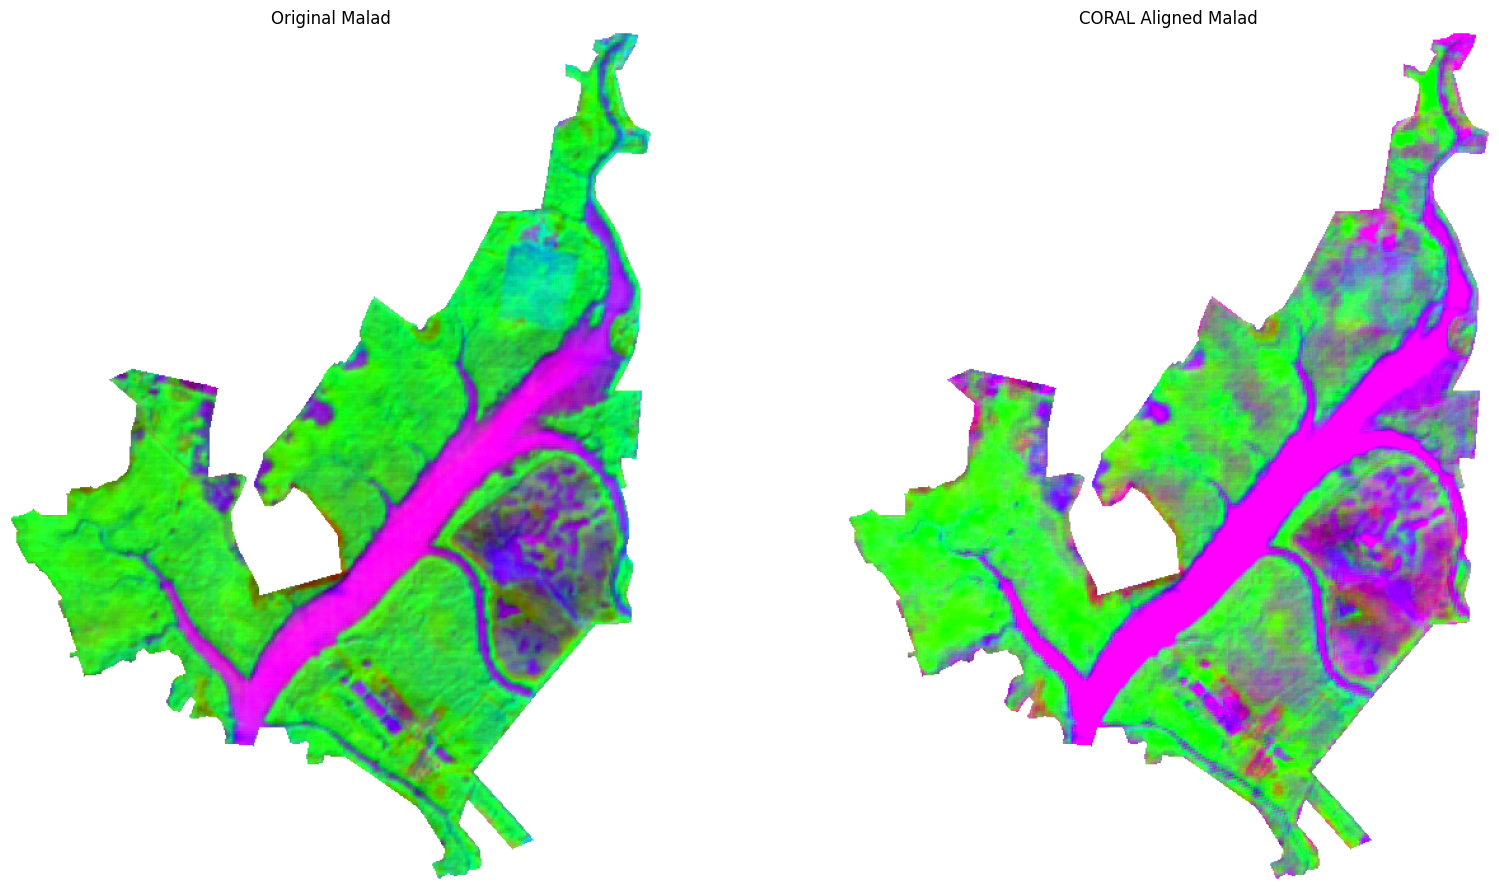

In [24]:
import matplotlib.pyplot as plt

fig,ax = plt.subplots(1,2,figsize=(18,9))

ax[0].imshow(orig_img)
ax[0].set_title("Original Malad")

ax[1].imshow(aligned_img)
ax[1].set_title("CORAL Aligned Malad")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()

In [25]:
prediction = rf.predict(aligned_pixels)

prediction_map = np.full(
    rows * cols,
    -1,
    dtype=np.int16
)

prediction_map[valid_mask] = prediction

prediction_map = prediction_map.reshape(rows, cols)

In [26]:
print(le.classes_)

['A_marina_dense' 'A_marina_moderate' 'Creek_Waterbody' 'Rhizophora_sp']


In [27]:
for cls, n in zip(*np.unique(prediction, return_counts=True)):
    print(le.classes_[cls], ":", n)

A_marina_dense : 37074
A_marina_moderate : 8753
Creek_Waterbody : 74135
Rhizophora_sp : 17062


In [28]:
import rasterio

profile.update(
    count=1,
    dtype=rasterio.int16,
    nodata=-1,
    compress="lzw"
)

prediction_tif = "Malad_RF_Prediction.tif"

with rasterio.open(prediction_tif, "w", **profile) as dst:
    dst.write(prediction_map.astype(np.int16), 1)

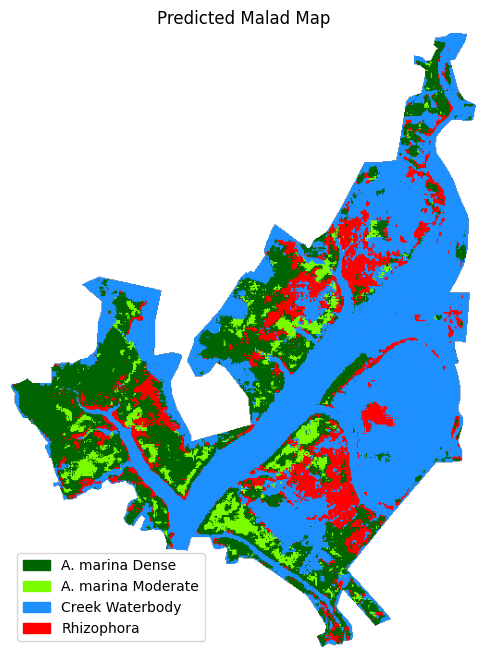

In [29]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import matplotlib.patches as mpatches
import numpy as np

# Make a copy for display
display = prediction_map.astype(float)

# NoData -> transparent
display[display == -1] = np.nan

# Four-class colormap
cmap = ListedColormap([
    "#006400",   # 0 Dense - Dark Green
    "#7CFC00",   # 1 Moderate - Light Green
    "#1E90FF",   # 2 Creek_Waterbody - Blue
    "#FF0000",   # 3 Rhizophora - Red
])

plt.figure(figsize=(10,8))

plt.imshow(
    display,
    cmap=cmap,
    vmin=0,
    vmax=3
)

plt.axis("off")
plt.title("Predicted Malad Map")

# Legend
legend = [
    mpatches.Patch(color="#006400", label="A. marina Dense"),
    mpatches.Patch(color="#7CFC00", label="A. marina Moderate"),
    mpatches.Patch(color="#1E90FF", label="Creek Waterbody"),
    mpatches.Patch(color="#FF0000", label="Rhizophora"),
]

plt.legend(
    handles=legend,
    loc="lower left",
    fontsize=10
)

plt.show()

In [34]:
print(le.classes_)

['A_marina_dense' 'A_marina_moderate' 'Creek_Waterbody' 'Rhizophora_sp']


In [35]:
import rasterio

profile_out = profile.copy()

profile_out.update(
    count=1,
    dtype=rasterio.int16,
    nodata=-1,
    compress="lzw"
)

prediction_file = "Malad_CORAL_RF.tif"

with rasterio.open(prediction_file, "w", **profile_out) as dst:
    dst.write(prediction_map.astype(np.int16), 1)

print("Prediction map saved.")

Prediction map saved.


In [36]:
import rasterio

src = rasterio.open(prediction_file)

print(src.count)
print(src.shape)

1
(691, 521)


In [37]:
label_mapping = {
    "am01": 0,   # Dense
    "am02": 1,   # Moderate
    "rh":   3    # Rhizophora
}

In [39]:
from rasterio.mask import mask
import numpy as np

y_true = []
y_pred = []
malad_gt=gpd.read_file(r"C:\Users\snvra\NISAR_Data_project\Data\malad_gt\malad_gt.shp")
gt = malad_gt.copy()

if gt.crs != src.crs:
    gt = gt.to_crs(src.crs)

for _, row in gt.iterrows():

    true_label = label_mapping[row["label"]]

    clipped, _ = mask(
        src,
        [row.geometry],
        crop=True,
        filled=False
    )

    pred = clipped.data[0]
    mask_pixels = clipped.mask[0]

    pred = pred[~mask_pixels]

    pred = pred[pred != -1]

    print(row["label"], len(pred))

    y_true.extend([true_label] * len(pred))
    y_pred.extend(pred.tolist())

rh 46
am01 207
am02 120


In [40]:
y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("Evaluation pixels:", len(y_true))

Evaluation pixels: 373


In [41]:
print("Ground Truth")
print(np.unique(y_true, return_counts=True))

print()

print("Predictions")
print(np.unique(y_pred, return_counts=True))

Ground Truth
(array([0, 1, 3]), array([207, 120,  46]))

Predictions
(array([0, 1, 2, 3]), array([179,  16, 120,  58]))


In [42]:
from sklearn.metrics import (
    accuracy_score,
    cohen_kappa_score,
    classification_report
)

oa = accuracy_score(y_true, y_pred)
kappa = cohen_kappa_score(y_true, y_pred)

print("Overall Accuracy :", oa)
print("Kappa :", kappa)

print()

print(classification_report(
    y_true,
    y_pred,
    labels=[0,1,3],
    target_names=[
        "Dense",
        "Moderate",
        "Rhizophora"
    ],
    zero_division=0
))

Overall Accuracy : 0.1742627345844504
Kappa : -0.17844247497127852

              precision    recall  f1-score   support

       Dense       0.30      0.26      0.28       207
    Moderate       0.12      0.02      0.03       120
  Rhizophora       0.16      0.20      0.17        46

   micro avg       0.26      0.17      0.21       373
   macro avg       0.19      0.16      0.16       373
weighted avg       0.23      0.17      0.19       373



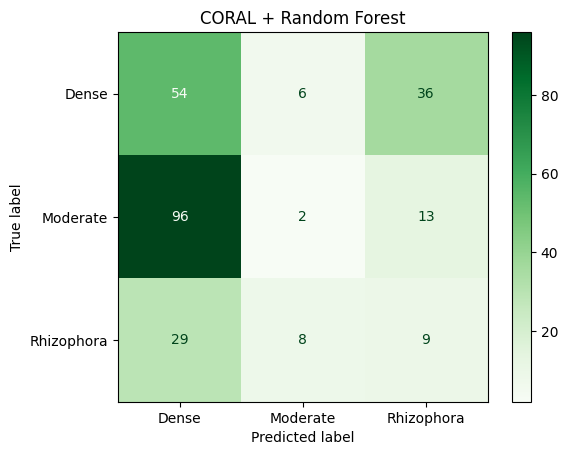

In [43]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

disp = ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    labels=[0,1,3],
    display_labels=[
        "Dense",
        "Moderate",
        "Rhizophora"
    ],
    cmap="Greens",
    values_format="d"
)

plt.title("CORAL + Random Forest")
plt.show()